In [1]:
import os
import torch
from torch import nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
from torch.utils.data import DataLoader
import utils  

# Set CUDA memory allocation configuration to limit the maximum split size.
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:64"

# Determine the device: use CUDA if available, otherwise fall back to CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Configure PyTorch's matmul precision for float32 to 'high'
torch.set_float32_matmul_precision('high')

# Enable the cudnn benchmark mode for potential performance improvements.
torch.backends.cudnn.benchmark = True

# Print the name of the CUDA device if CUDA is available.
if torch.cuda.is_available():
    print("CUDA Device:", torch.cuda.get_device_name())
else:
    print("CUDA is not available. Using CPU.")

CUDA Device: NVIDIA A100 80GB PCIe


# Loading the CIFAR10 dataset and create DataLoaders

In [2]:
# Define the batch size.
BATCH_SIZE = 512

# Load CIFAR10 dataset using load_data_cifar10 function in utils.py
train_iter, test_iter = utils.load_data_cifar10(BATCH_SIZE)

Files already downloaded and verified
Files already downloaded and verified


# Defining the Model

In [3]:
class ExpertBranch(nn.Module):
    """
    ExpertBranch module computes the gating values for each expert.
    
    Attributes:
        gate (nn.Sequential): A sequential module combining adaptive pooling,
                              linear transformations, activation, dropout, and softmax.
    """
    def __init__(self, in_channels: int, num_experts: int, factor: int) -> None:
        """
        Initialise the ExpertBranch.

        Args:
            in_channels (int): The number of input channels.
            num_experts (int): The number of experts.
            factor (int): Reduction factor for the intermediate channel size.
        """
        super().__init__()
        reduced_channels = in_channels // factor
        self.gate = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(in_channels, reduced_channels),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.2),
            nn.Linear(reduced_channels, num_experts),
            nn.Softmax(dim=-1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass to compute and reshape gating values.

        Args:
            x (torch.Tensor): The input tensor.

        Returns:
            torch.Tensor: The reshaped gating tensor with dimensions 
                          (batch_size, num_experts, 1, 1, 1).
        """
        gating = self.gate(x)
        gating = gating.view(gating.size(0), -1, 1, 1, 1)
        return gating


class MathisBlock(nn.Module):
    """
    A convolutional block that integrates multiple expert layers combined with a residual connection.
    """
    def __init__(self, in_channels: int, out_channels: int, num_experts: int,
                 factor: int, downsample: bool = False) -> None:
        """
        Initialise the MathisBlock.

        Args:
            in_channels (int): The number of input channels.
            out_channels (int): The number of output channels.
            num_experts (int): The number of expert layers.
            factor (int): Reduction factor used in the ExpertBranch.
            downsample (bool): Flag to indicate if spatial downsampling is applied.
        """
        super().__init__()
        self.num_experts = num_experts
        stride = 2 if downsample else 1

        self.expert_branch = ExpertBranch(in_channels, num_experts, factor)

        self.expert_layers = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(in_channels)
            )
            for _ in range(num_experts)
        ])

        self.project = nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride)
        self.skip = (nn.Identity() if not downsample and in_channels == out_channels 
                     else nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride))

        self.bn_after_skip = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass of the MathisBlock.

        Args:
            x (torch.Tensor): The input tensor.

        Returns:
            torch.Tensor: The output tensor after expert fusion and residual connection.
        """
        # Compute gating weights for the expert branches.
        gating = self.expert_branch(x)

        # Apply each expert layer with activation.
        expert_outputs = [self.relu(layer(x)) for layer in self.expert_layers]
        expert_outputs = torch.stack(expert_outputs, dim=1)

        # Combine the expert outputs using the gating weights.
        combined = (expert_outputs * gating).sum(dim=1)
        combined = self.project(combined)

        # Implement the residual connection.
        out = self.skip(x) + combined
        out = self.bn_after_skip(out)
        return self.relu(out)


class MathisNet(nn.Module):
    """
    MathisNet constructs a convolutional network by combining an initial stem,
    multiple MathisBlocks, and a final classifier head.
    """
    def __init__(self, conv_arch: list, num_outputs: int) -> None:
        """
        Initialise the MathisNet.

        Args:
            conv_arch (list): A list of tuples defining each block's configuration.
                              Each tuple should contain (out_channels, num_experts, factor, downsample).
            num_outputs (int): The number of output classes.
        """
        super().__init__()
        stem_out_channels = conv_arch[0][0]

        self.stem = nn.Sequential(
            nn.Conv2d(3, stem_out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(stem_out_channels),
            nn.ReLU(inplace=True)
        )

        in_channels = stem_out_channels
        self.blocks = nn.ModuleList()
        for (out_channels, num_experts, factor, downsample) in conv_arch:
            self.blocks.append(MathisBlock(in_channels, out_channels, num_experts, factor, downsample))
            in_channels = out_channels

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(p=0.2),
            nn.Linear(in_channels, num_outputs)
        )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass through MathisNet.

        Args:
            x (torch.Tensor): The input tensor.

        Returns:
            torch.Tensor: The final classification output.
        """
        x = self.stem(x)
        for block in self.blocks:
            x = block(x)
        x = self.classifier(x)
        return x


# Initialise Model and Weights

In [4]:
def init_weights(m: nn.Module) -> None:
    """
    Initialise weights for Conv2d and Linear layers using Kaiming normalisation.
    
    Args:
        m (nn.Module): A module instance, for which the weights and biases are initialised.
    """
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        torch.nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
        if m.bias is not None:
            nn.init.constant_(m.bias, 0)

# Define the convolutional architecture as a list of tuples.
conv_arch = [
    (96,  4, 2, False),  
    (128, 6, 4, True),   
    (256, 6, 4, False),  
    (256, 8, 4, True),   
    (512, 8, 4, True),   
]

num_outputs = 10

# Instantiate the model with the given architecture and number of output classes.
model = MathisNet(conv_arch, num_outputs)

# Apply the custom weight initialisation to relevant layers.
model.apply(init_weights)

# Move the model to the specified device (e.g., GPU or CPU).
model = model.to(device)

# Compile the model for optimisation.
model = torch.compile(model)

print(model)

OptimizedModule(
  (_orig_mod): MathisNet(
    (stem): Sequential(
      (0): Conv2d(3, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (blocks): ModuleList(
      (0): MathisBlock(
        (expert_branch): ExpertBranch(
          (gate): Sequential(
            (0): AdaptiveAvgPool2d(output_size=(1, 1))
            (1): Flatten(start_dim=1, end_dim=-1)
            (2): Linear(in_features=96, out_features=48, bias=True)
            (3): ReLU(inplace=True)
            (4): Dropout(p=0.2, inplace=False)
            (5): Linear(in_features=48, out_features=4, bias=True)
            (6): Softmax(dim=-1)
          )
        )
        (expert_layers): ModuleList(
          (0-3): 4 x Sequential(
            (0): Conv2d(96, 96, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_run

# Loss and Optimisation Algorithms

In [5]:
# Define loss function with label smoothing
loss = nn.CrossEntropyLoss(label_smoothing=0.05)

# Hyperparameters
LEARNING_RATE = 0.05
WEIGHT_DECAY = 5e-4
MOMENTUM = 0.9

# Initialise the optimiser (SGD with Nesterov momentum)
optimiser = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    nesterov=True
)

# Training functions

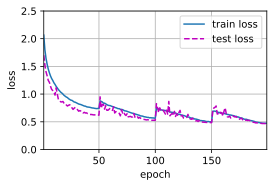

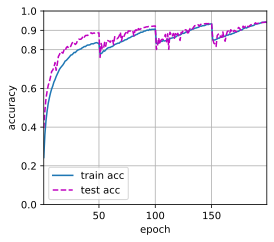

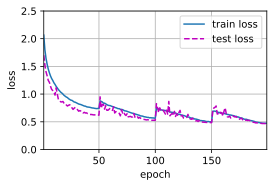

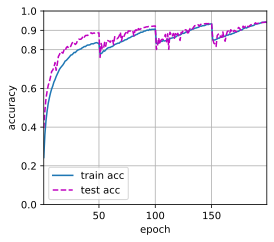

In [6]:
# Define the number of epochs.
NUM_EPOCHS = 199

# Initialise the cosine annealing scheduler with warm restarts.
scheduler = CosineAnnealingWarmRestarts(
    optimiser,   
    T_0=50,     
    T_mult=1,   
    eta_min=1e-5
)

# Begin training using train function in utils.py.
utils.train(
    model,
    train_iter,
    test_iter,
    loss,      
    NUM_EPOCHS,
    optimiser,
    scheduler
)

In [7]:
def test_model(model: nn.Module, test_loader: DataLoader) -> float:
    """
    Evaluate the model on the test dataset and print the accuracy.

    Args:
        model (nn.Module): The PyTorch model to be tested.
        test_loader (DataLoader): DataLoader for the test dataset.

    Returns:
        float: The test accuracy as a decimal.
    """
    model.eval()  # Set the model to evaluation mode.
    with torch.no_grad():
        acc = utils.evaluate_accuracy(model, test_loader, device)
    print(f"✅ Test Accuracy: {acc * 100:.2f}%")
    return acc

# Evaluate the model and print the accuracy.
print(test_model(model, test_iter))

✅ Test Accuracy: 94.32%
0.9432
